# 다항회귀(Polynomial Regression)
- 선형적인 그래프(직선)로 데이터를 표현하기 어려운 경우 -> 비선형 데이터
-이러한 비선형 데이터를 학습하기 위해 다차원식을 만드는 기법이 다향회귀

In [29]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [30]:
# 25입력받아, 산점도 그래프에 표시하고 곡선도 출력하시오
# 

In [31]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [32]:
# 데이터 분리
train_data, test_data, train_label, test_label= train_test_split(perch_length,perch_weight)

reshape는 배열에 들어 있는 값은 그대로 두고, 배열의 모양만 바꾸는 기능
**NumPy 라이브러리의 배열이 제공하는 메서드(기능)**

1. reshape(행 개수, 열 개수)
예로 
import numpy as np

data = np.array([10, 20, 30, 40, 50, 60])

print(data.reshape(2, 3))
의 결과는
[[10 20 30]
 [40 50 60]]

2. reshape(-1, 1)의 -1은 NumPy가 정한 특별한 약속으로, **“이쪽 개수는 알아서 계산해 주세요”**라는 뜻

data.reshape(-1, 1) : 열을 1개로 지정했으니, 값이 6개라면 행은 자동으로 6개

In [33]:
# 2차원 배열로 변경
train_data=train_data.reshape(-1,1)
test_data=test_data.reshape(-1,1)

print('train_data:',train_data[:2])

train_data: [[36.5]
 [35. ]]


In [34]:
# 다항회귀 데이터전처리
# train_data [[43.5**2, 43.5]]
# numpy column_stack(())=np.column_stack(()) 는 여러값을 한행, 개수만큼의 열로 묶어주는것.


train_poly=np.column_stack((train_data**2,train_data))
test_poly=np.column_stack((test_data**2,test_data))


LinearRegression은 다음 방식으로 예측
-길이² × a + 길이 × b + c

In [35]:
# 모델에 데이터 학습
lr=LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
result= lr.predict(test_poly)
print("무게예측:",result)

# 정확도
score = lr.score(train_poly, train_label)
score2= lr.score(test_poly,test_label)
print('train:',score)
print('test:',score2)

무게예측: [ 810.25895917  869.51053598  116.39973378  142.21110594  276.3364946
   33.9533515   166.07946399   71.06861534  810.25895917  698.18911805
  131.08109098 1127.96121822  300.0244893   994.4470021 ]
train: 0.9686141498860102
test: 0.9791370569777763


In [36]:
#  이미 정수로 받으므로 변환 불필요
in_data=25
result=lr.predict([[in_data**2,in_data]])
print("예측무게:",result)


예측무게: [205.90282138]


예측 무게 = a × 길이² + b × 길이 + c

코드            | 의미              | 식에서의 위치 |

- lr.coef_[0]:     길이²에 곱하는 계수         a
- lr.coef_[1] :    길이에 곱하는 계수          b
- lr.intercept_ :  마지막에 더하는 상수항      c

In [37]:
print(lr.coef_)
print(lr.intercept_)

[  1.07221875 -25.45370446]
172.10871391182502


In [38]:
lr.coef_[0]

np.float64(1.0722187501816942)

In [39]:
# 그래프를 그릴 범위 (15~49)

point = np.arange(0,50)

In [40]:
point[:5]

array([0, 1, 2, 3, 4])

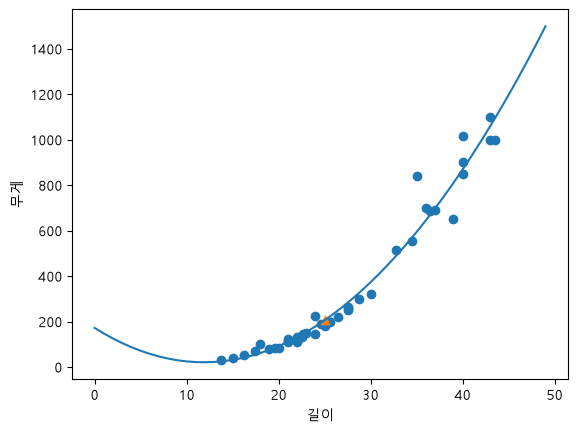

In [41]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.83, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()